In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sea 

In [4]:
## loading ~ repeated boring stuff
df = pd.read_csv("q1_working.csv")

metrics = ["Age", "Height", "Weight", "BMI"]

In [6]:
sea.set_theme(style="whitegrid")

### Bar Graphs

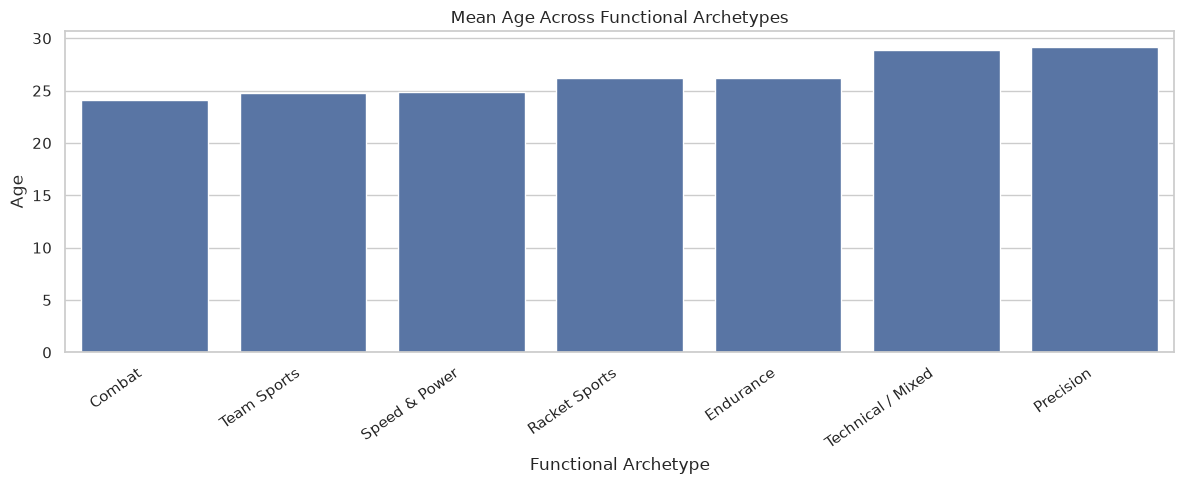

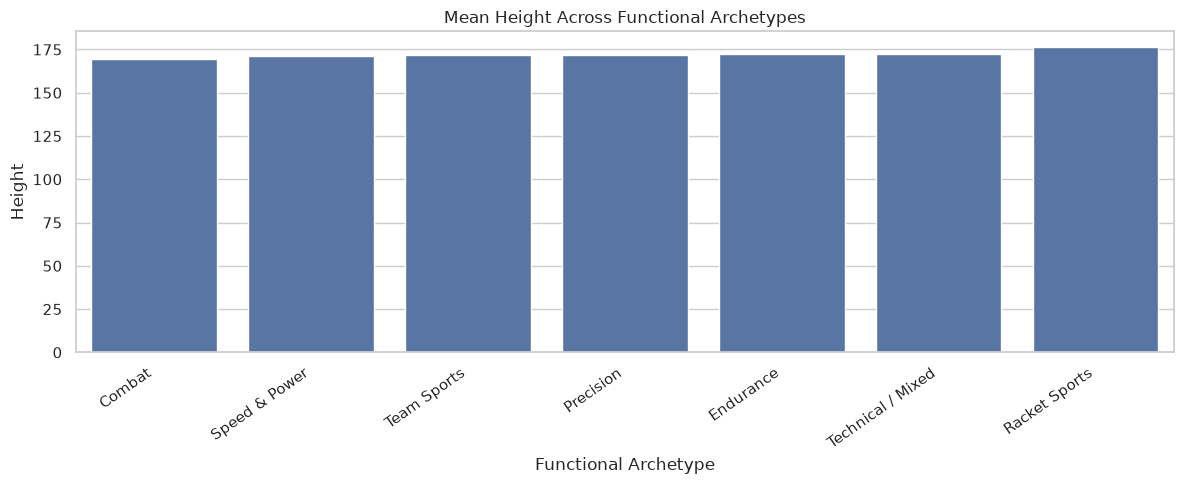

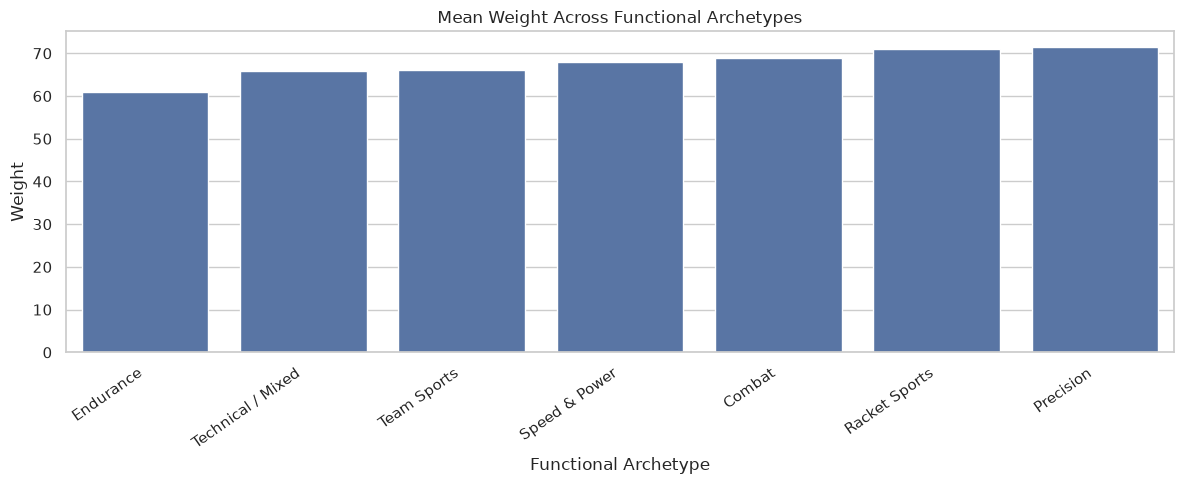

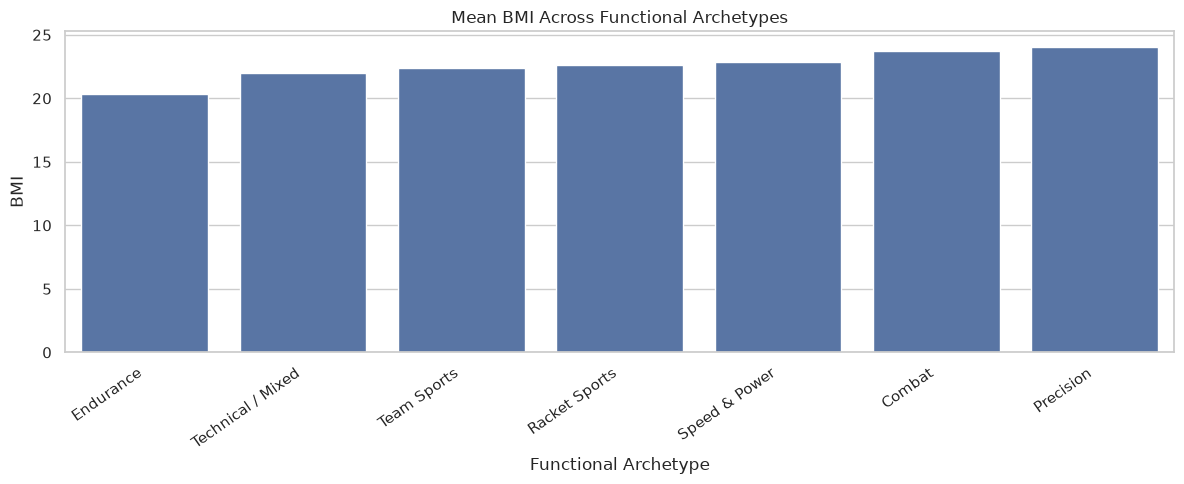

In [7]:
# plot the mean of each metric across functional archetypes
for metric in metrics:
    plt.figure(figsize=(12, 5))

    # sort archetypes by their mean metric value (ascending)
    order = (
        df.groupby("Archetype")[metric]
        .mean()
        .sort_values()
        .index
    )

    # create a bar plot showing the mean for each archetype
    sea.barplot(
        data=df,
        x="Archetype",
        y=metric,
        order=order,
        errorbar=None
    )

    # add title and axis labels
    plt.title(f"Mean {metric} Across Functional Archetypes")
    plt.xlabel("Functional Archetype")
    plt.ylabel(metric)

    # Rotate labels for better readability
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

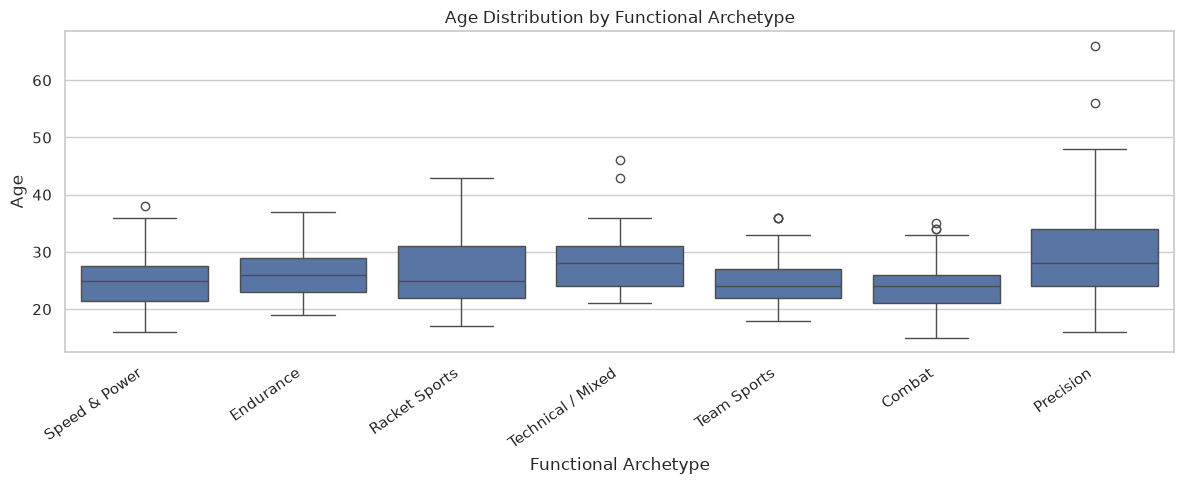

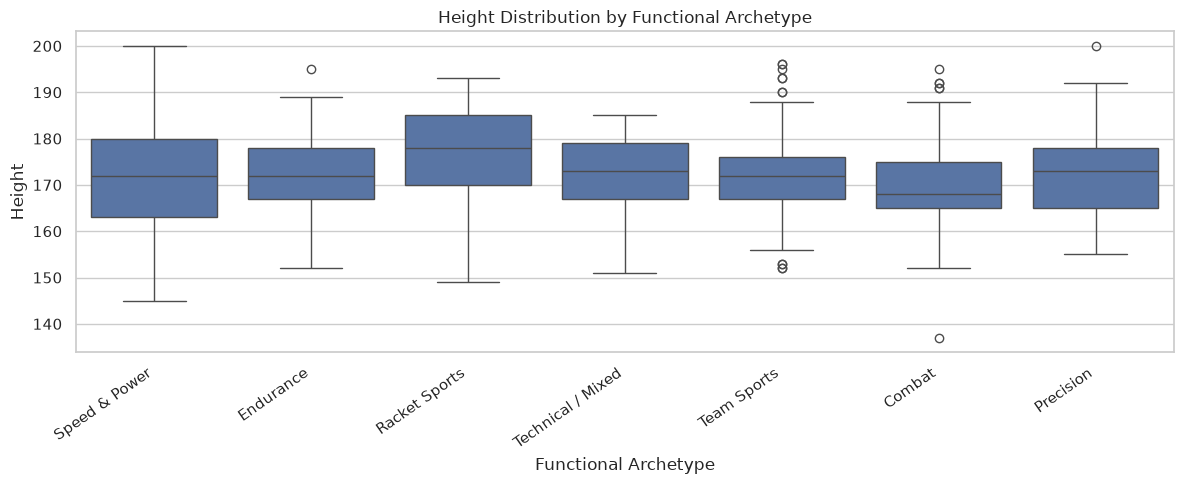

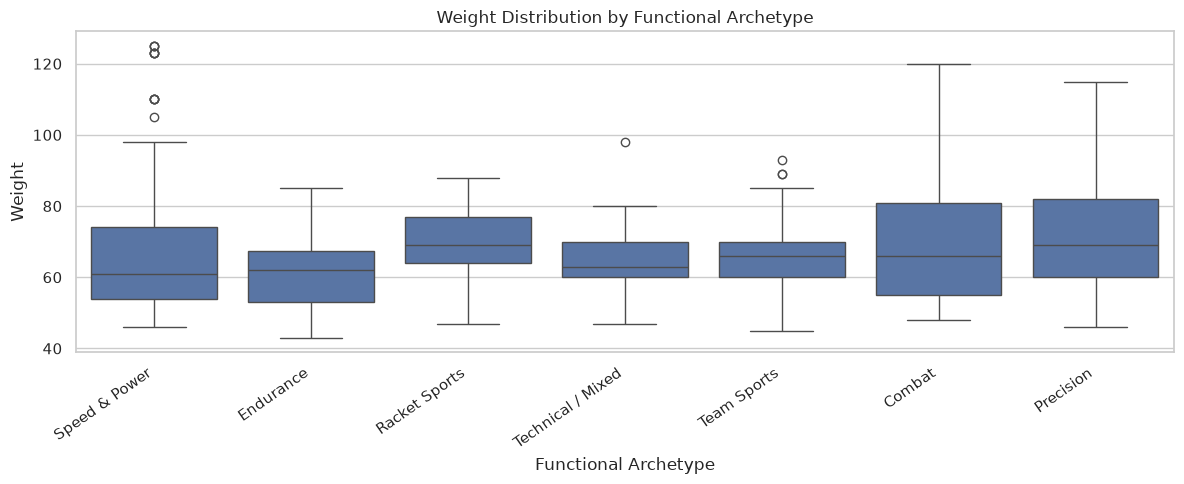

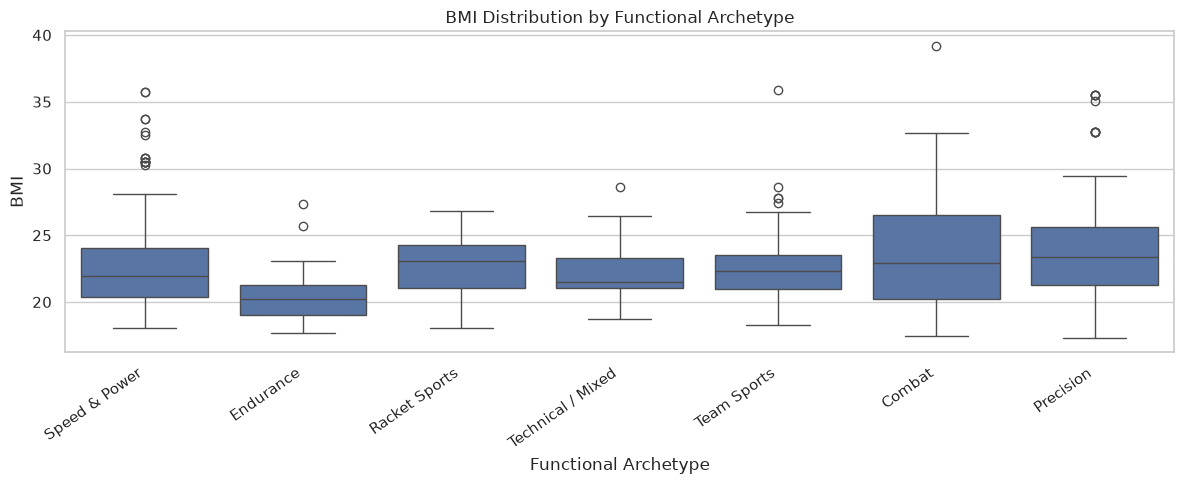

In [8]:
## Boxplots
for metric in metrics:
    plt.figure(figsize=(12, 5))

    sea.boxplot(
        data=df,
        x="Archetype",
        y=metric
    )

    plt.title(f"{metric} Distribution by Functional Archetype")
    plt.xlabel("Functional Archetype")
    plt.ylabel(metric)
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

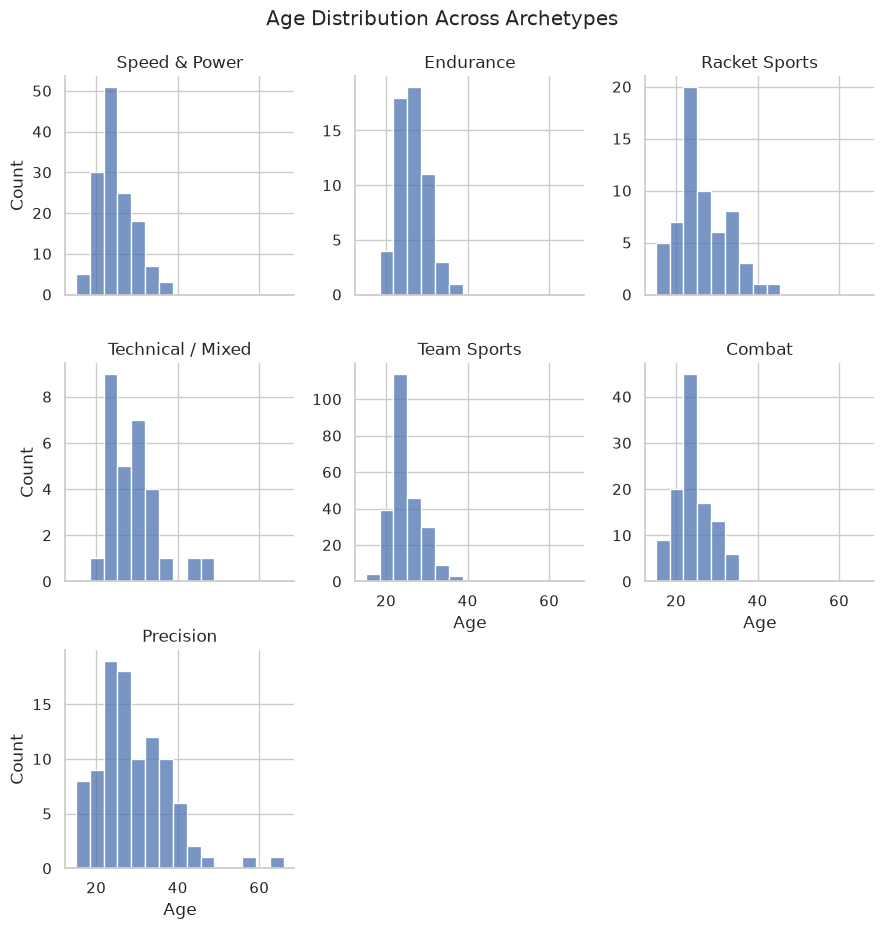

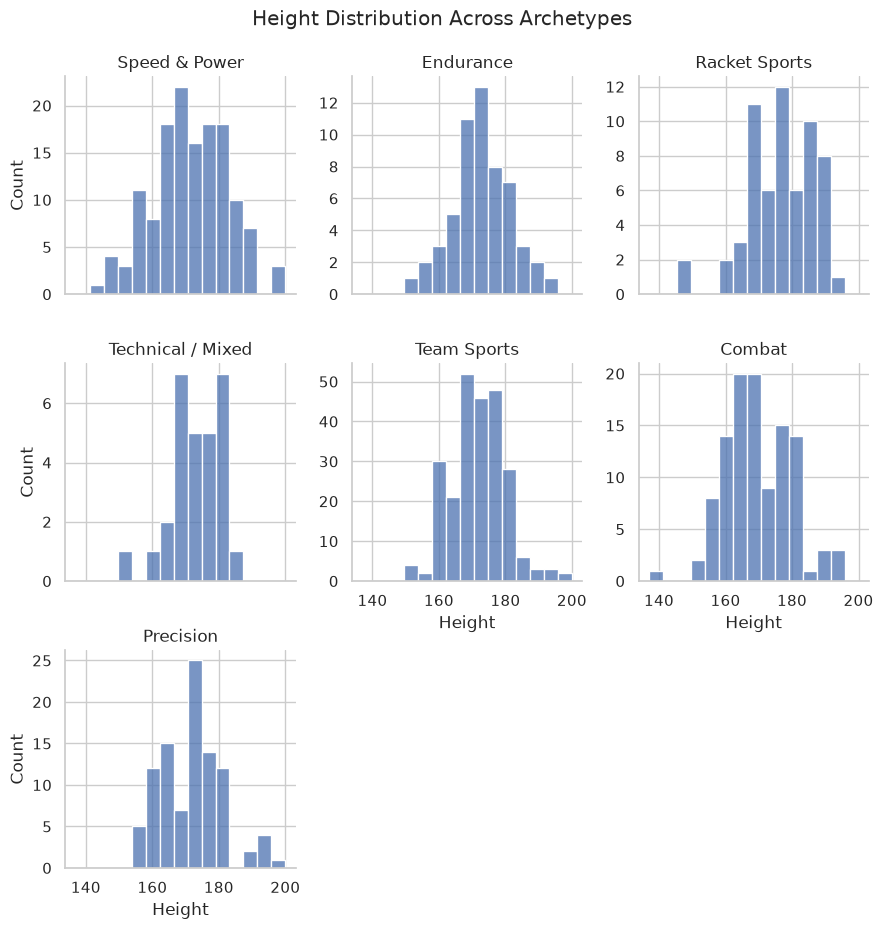

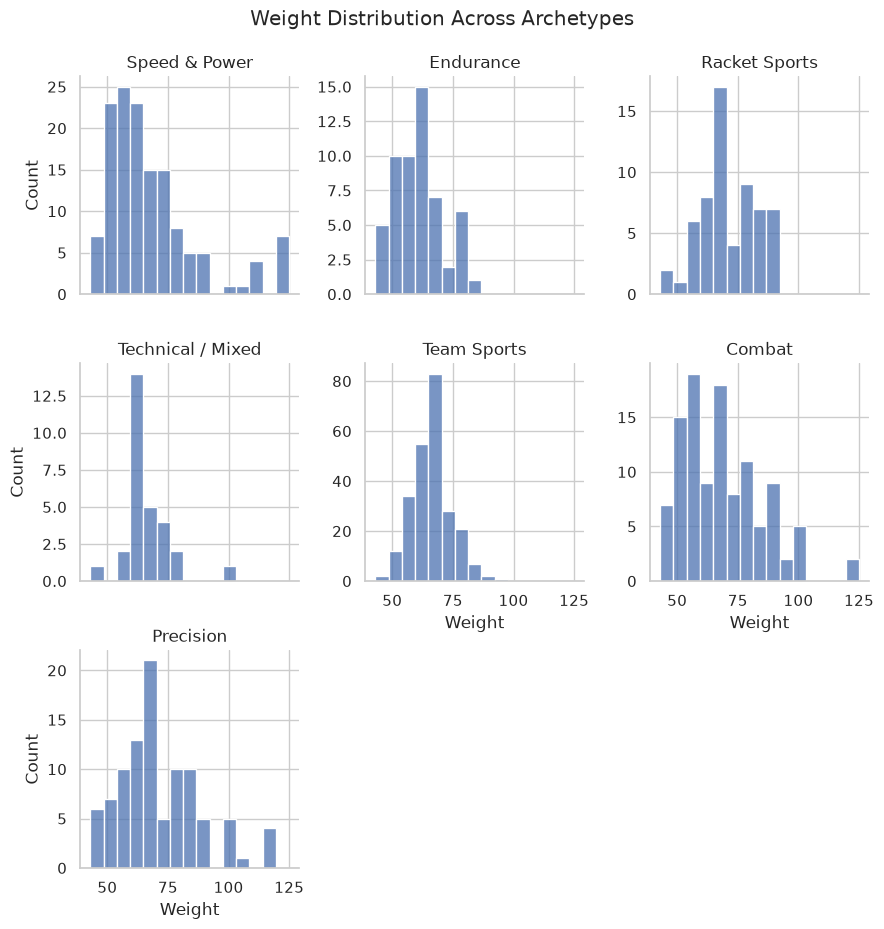

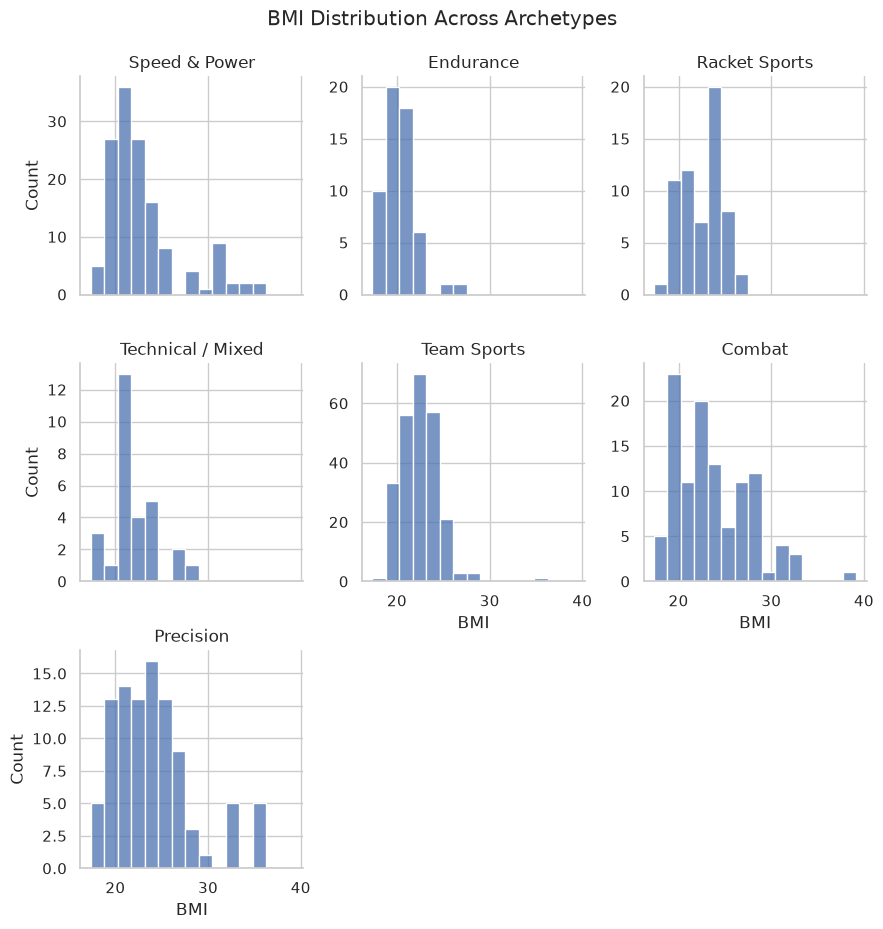

In [9]:
## Histograms
for metric in metrics:
    g = sea.displot(
        data=df,
        x=metric,
        col="Archetype",
        col_wrap=3,
        bins=15,
        height=3,
        facet_kws={"sharex": True, "sharey": False}
    )

    g.set_titles("{col_name}")
    g.fig.suptitle(
        f"{metric} Distribution Across Archetypes",
        y=1.03
    )

    plt.show()

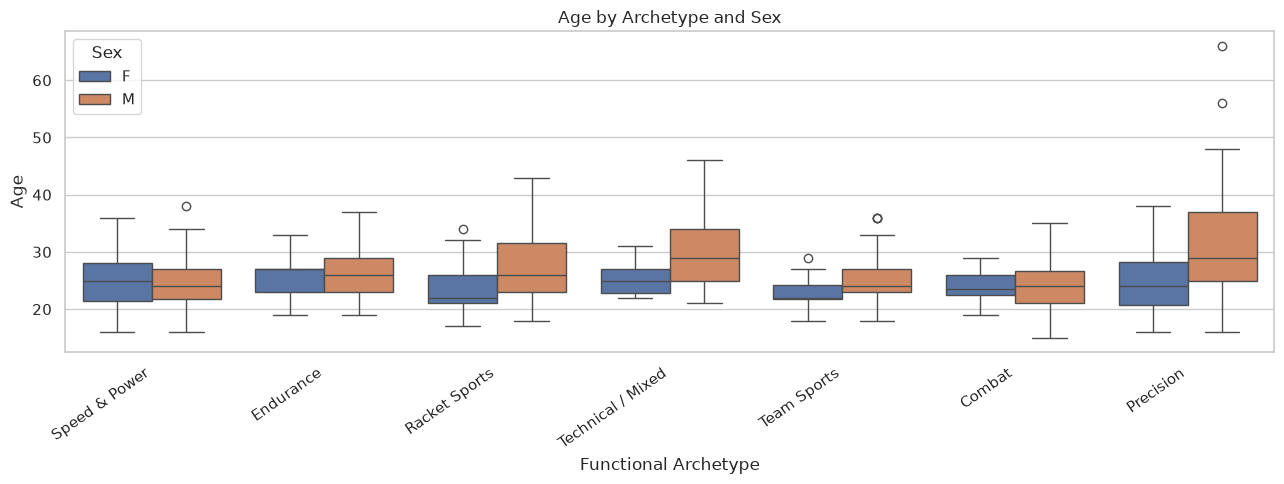

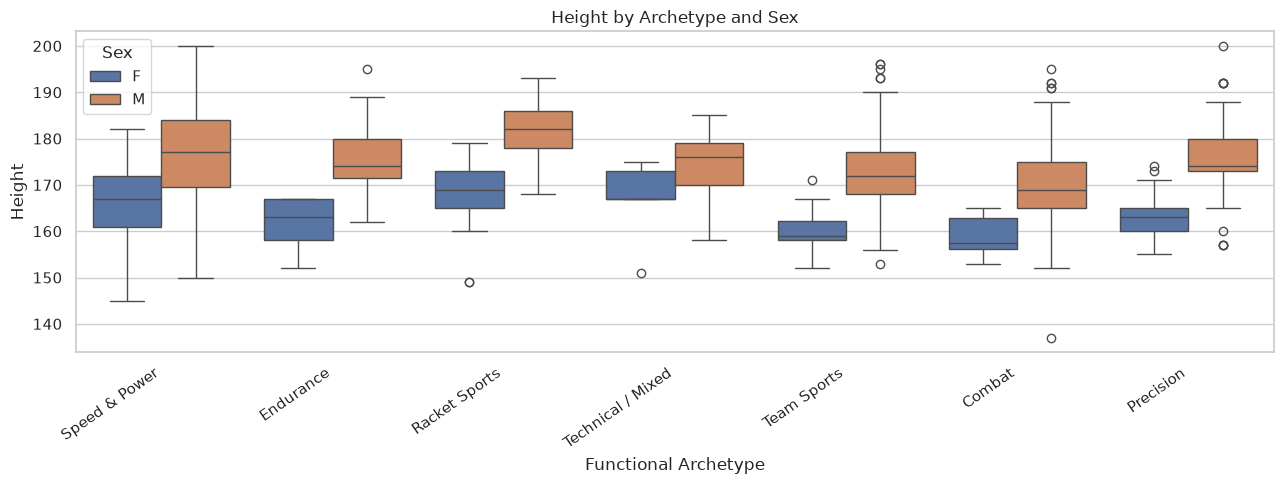

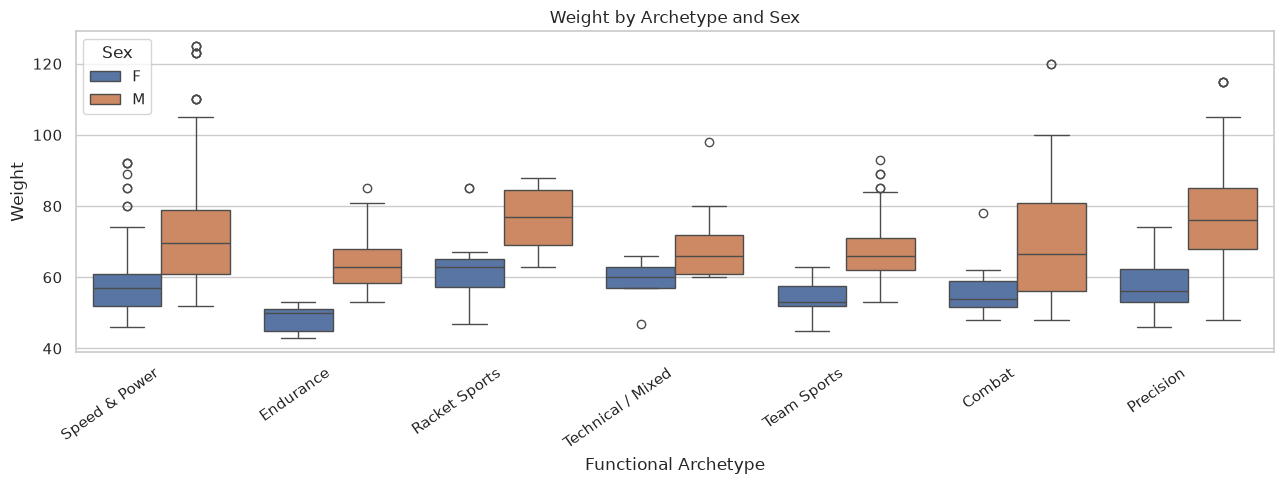

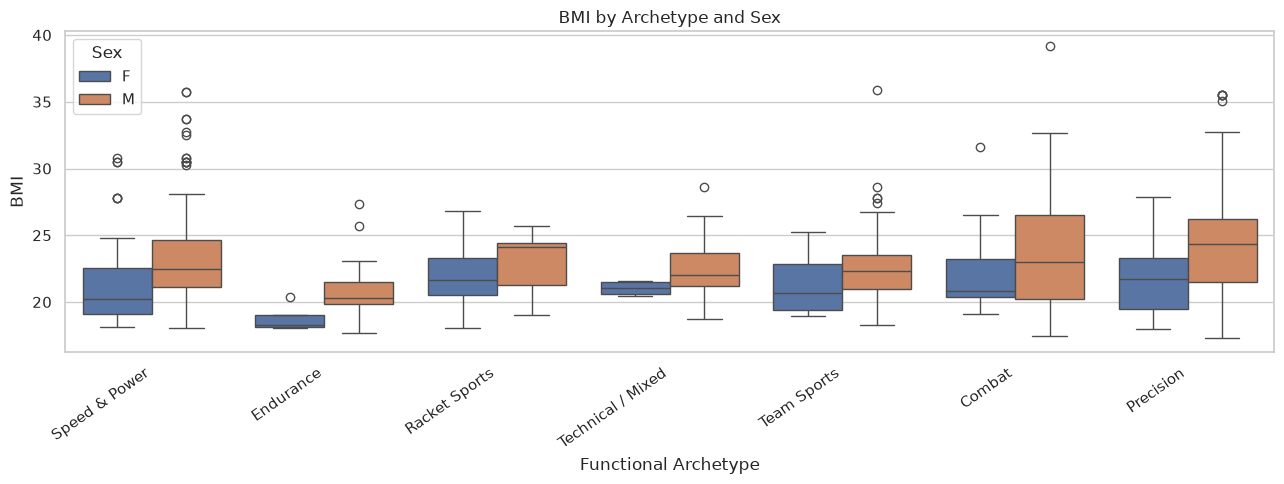

In [10]:
## gender_wise boxplot
for metric in metrics:
    plt.figure(figsize=(13, 5))

    sea.boxplot(
        data=df,
        x="Archetype",
        y=metric,
        hue="Sex"
    )

    plt.title(f"{metric} by Archetype and Sex")
    plt.xlabel("Functional Archetype")
    plt.ylabel(metric)
    plt.xticks(rotation=35, ha="right")
    plt.legend(title="Sex")
    plt.tight_layout()
    plt.show()

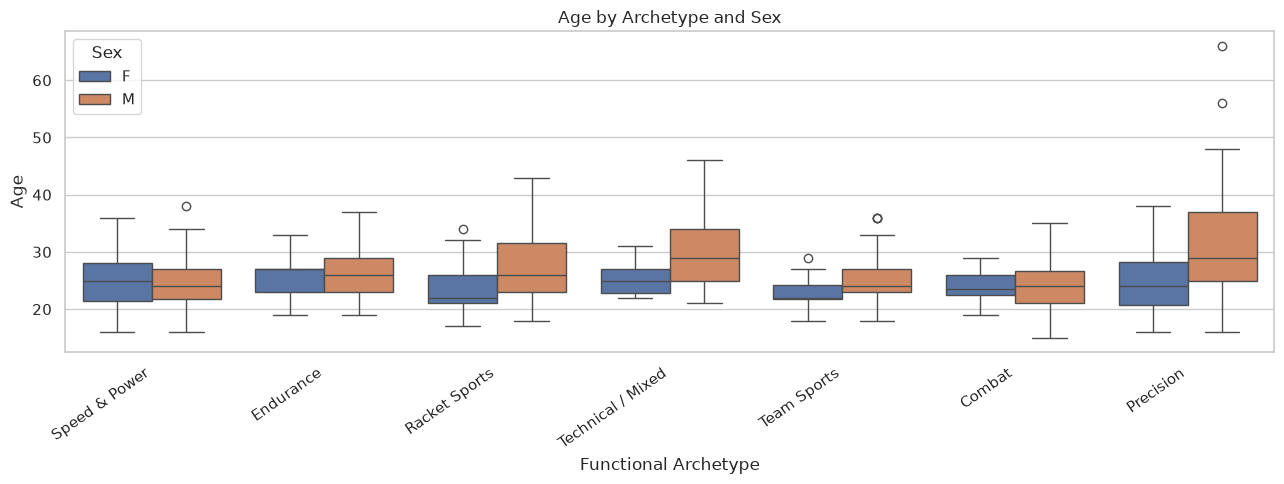

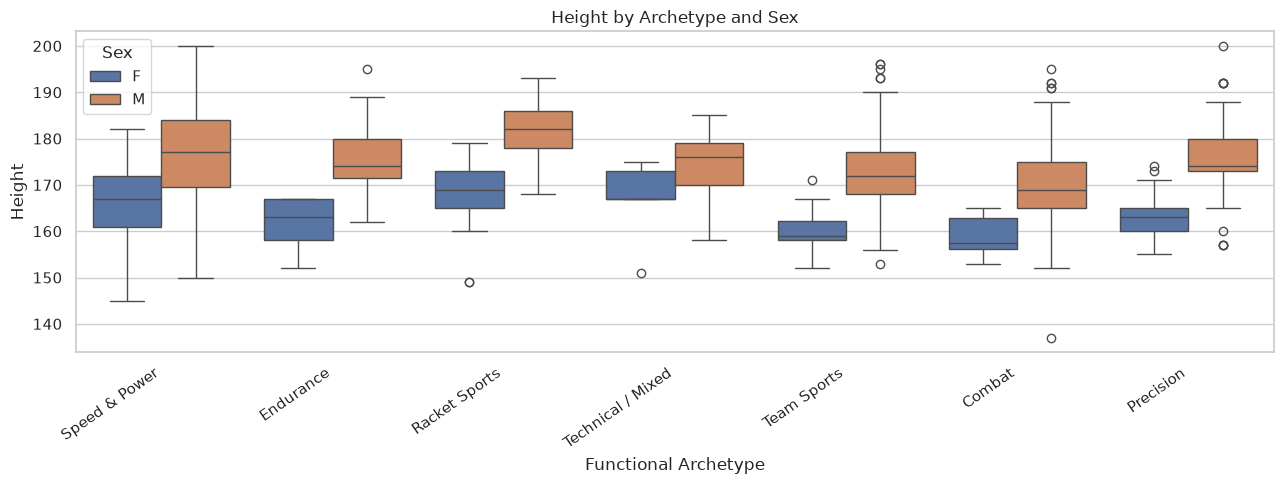

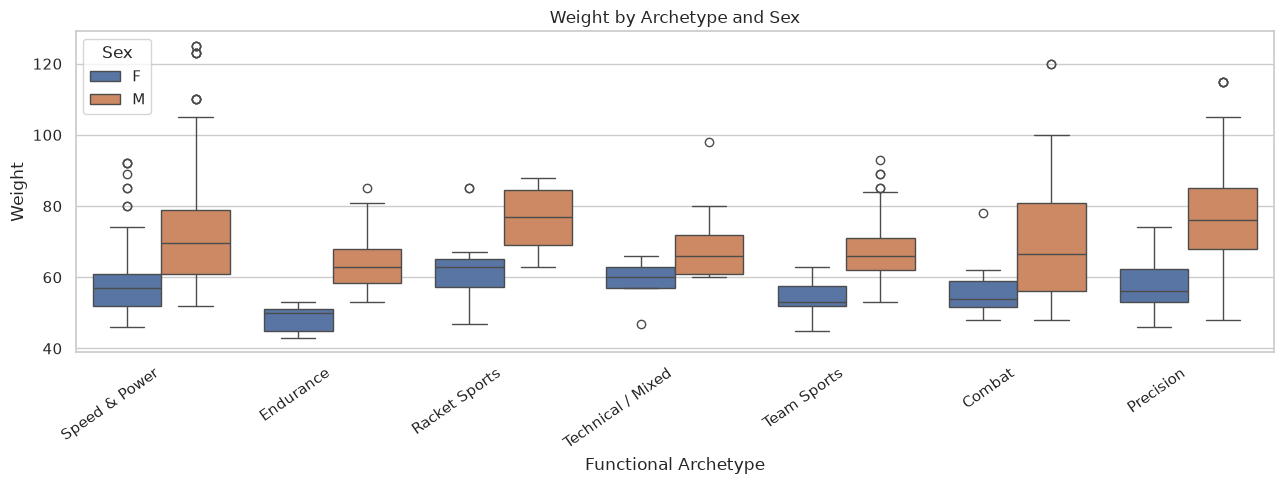

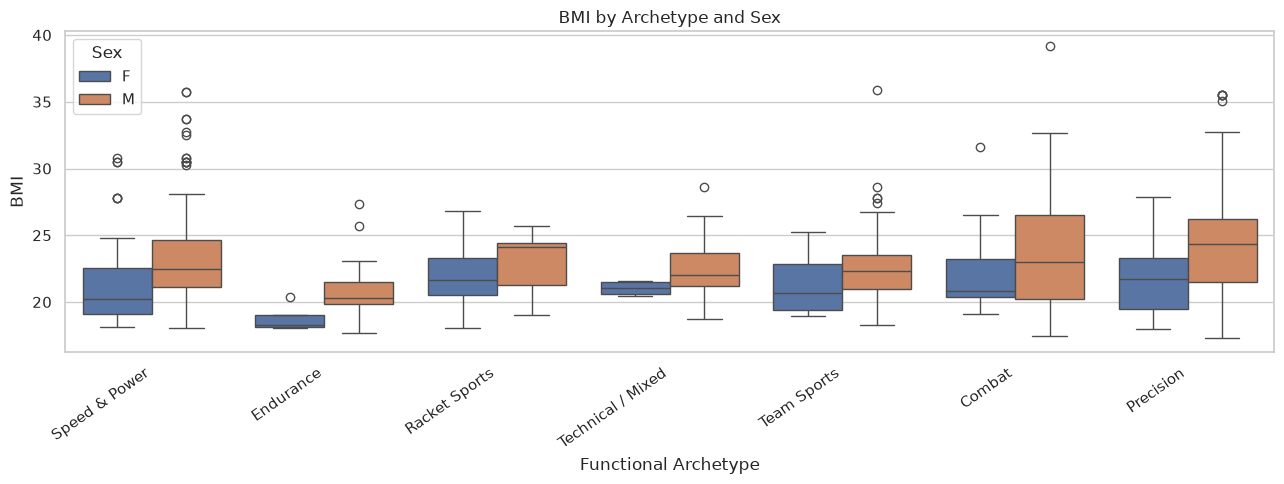

In [11]:
## Height vs weight
for metric in metrics:
    plt.figure(figsize=(13, 5))

    sea.boxplot(
        data=df,
        x="Archetype",
        y=metric,
        hue="Sex"
    )

    plt.title(f"{metric} by Archetype and Sex")
    plt.xlabel("Functional Archetype")
    plt.ylabel(metric)
    plt.xticks(rotation=35, ha="right")
    plt.legend(title="Sex")
    plt.tight_layout()
    plt.show()

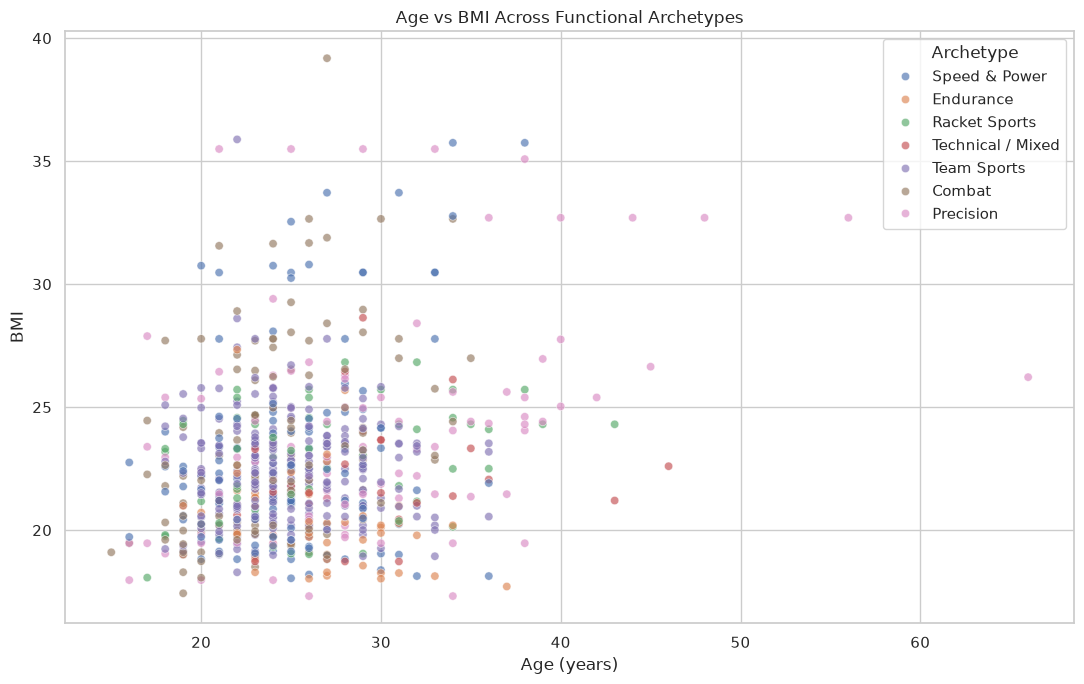

In [12]:
# Age vs BMI 
plt.figure(figsize=(11, 7))

sea.scatterplot(
    data=df,
    x="Age",
    y="BMI",
    hue="Archetype",
    alpha=0.65
)

plt.title("Age vs BMI Across Functional Archetypes")
plt.xlabel("Age (years)")
plt.ylabel("BMI")
plt.tight_layout()
plt.show()

NameError: name 'stats' is not defined

<Figure size 600x500 with 0 Axes>

### Saving the plots
<a href="https://chatgpt.com/s/t_6aea19f880108191b9fed75f35429787" target="_blank">
    LLM help to save them
</a>

In [ ]:
from pathlib import Path

base = Path("q1_plots")

folders = {
    "mean": base / "mean_comparison",
    "box": base / "boxplots",
    "hist": base / "histograms",
    "sex": base / "sexwise_boxplots",
    "height_weight": base / "scatterplots",
    "age_bmi": base / "scatterplots"
}

for folder in folders.values():
    folder.mkdir(parents=True, exist_ok=True)

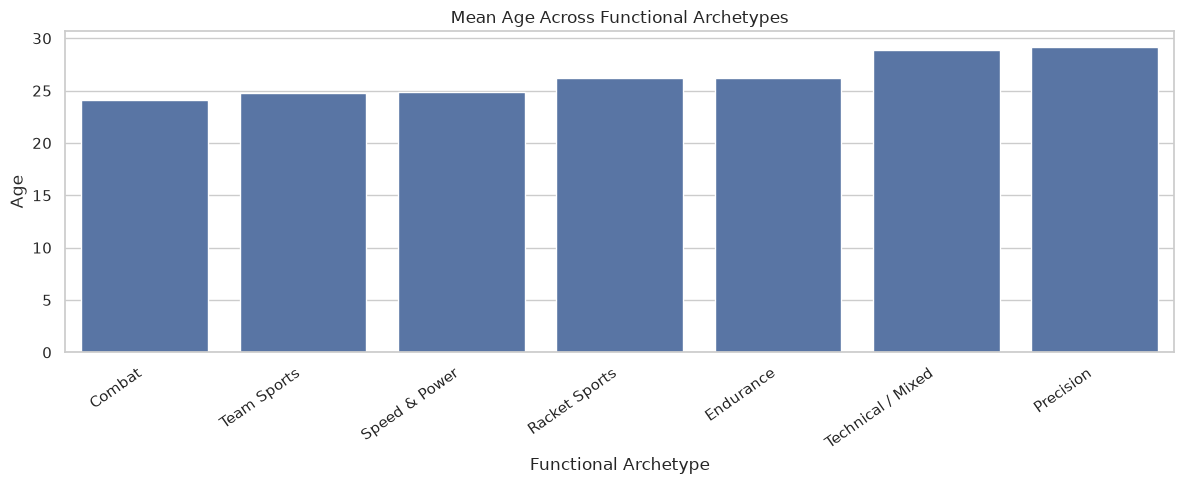

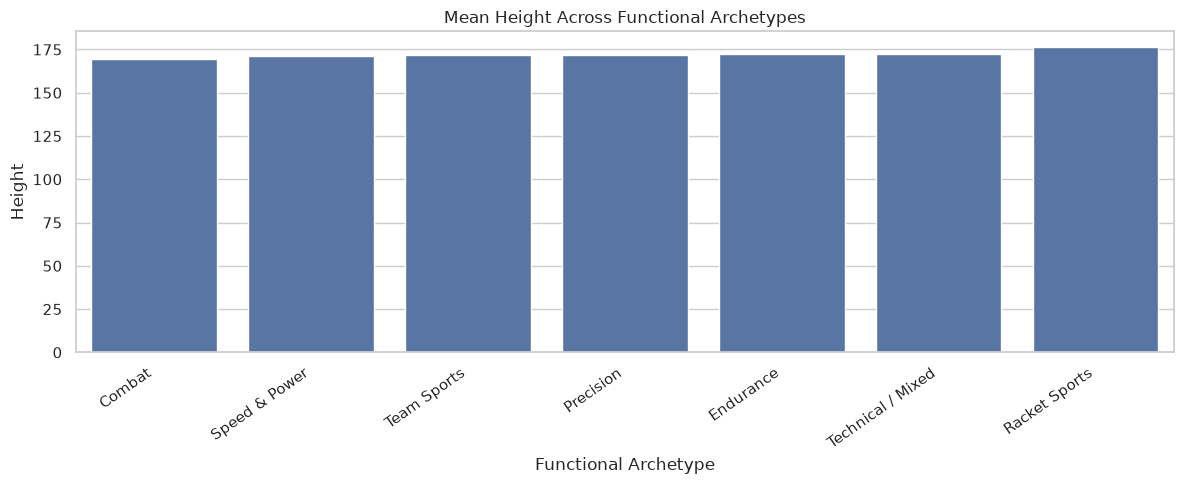

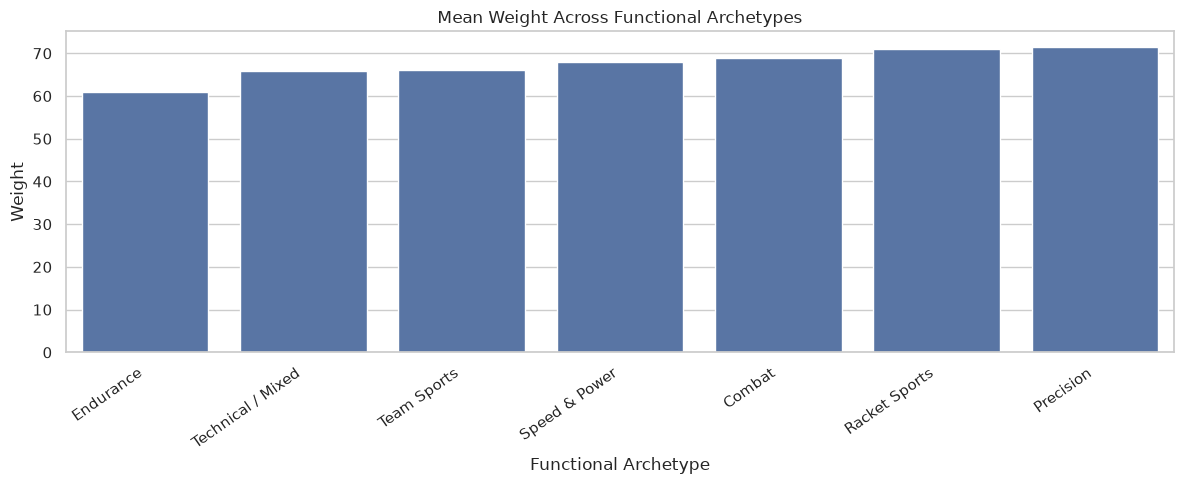

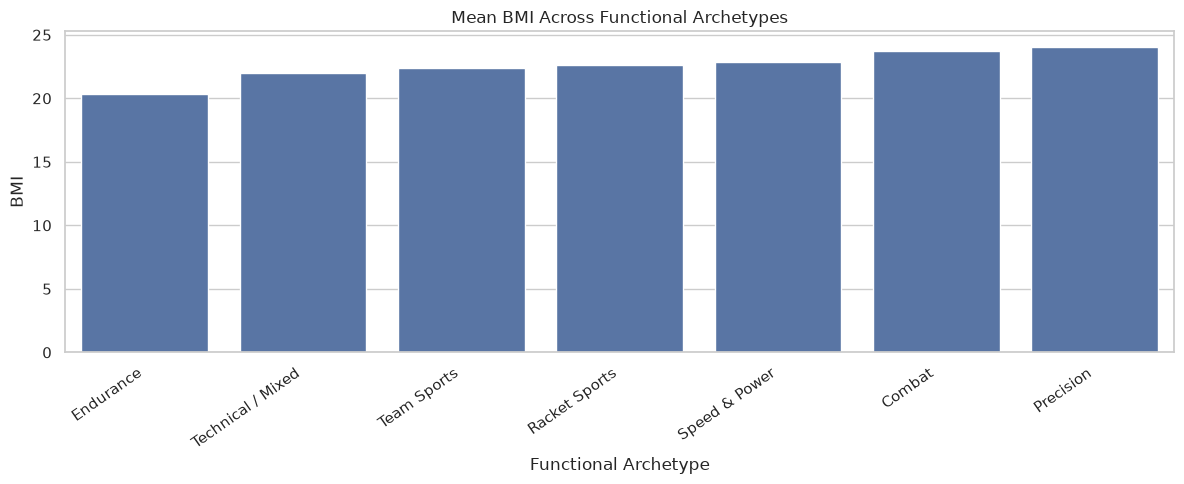

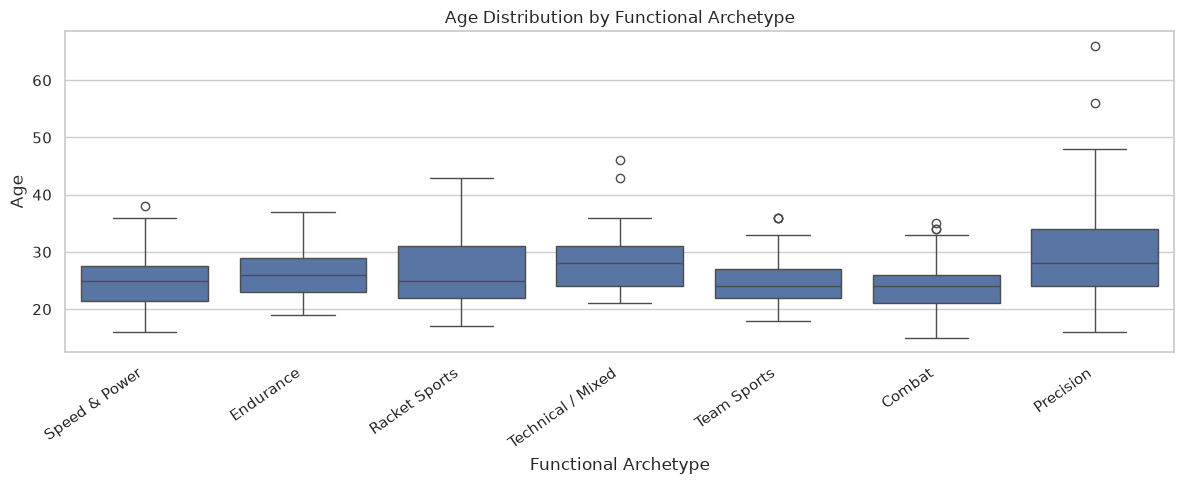

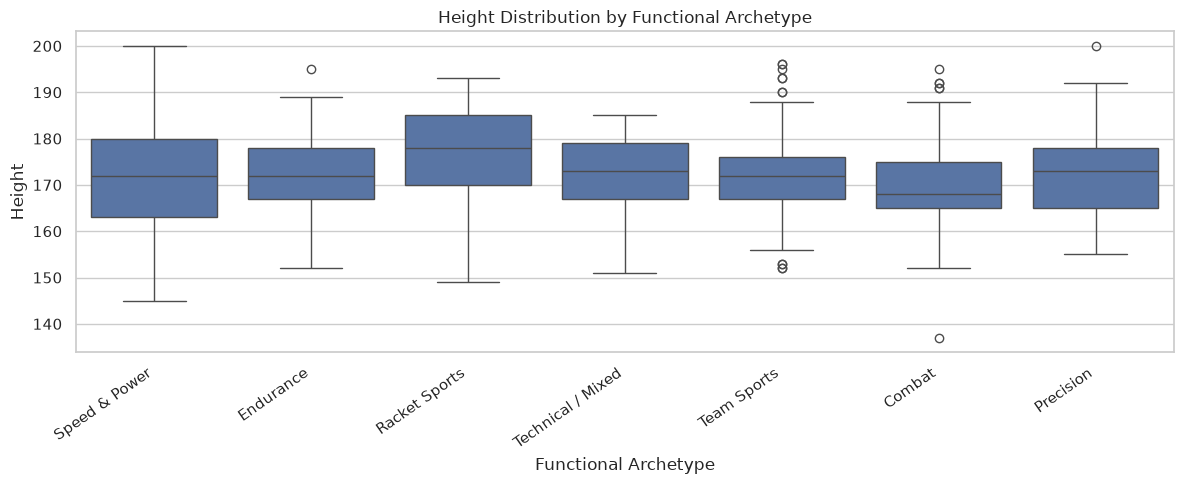

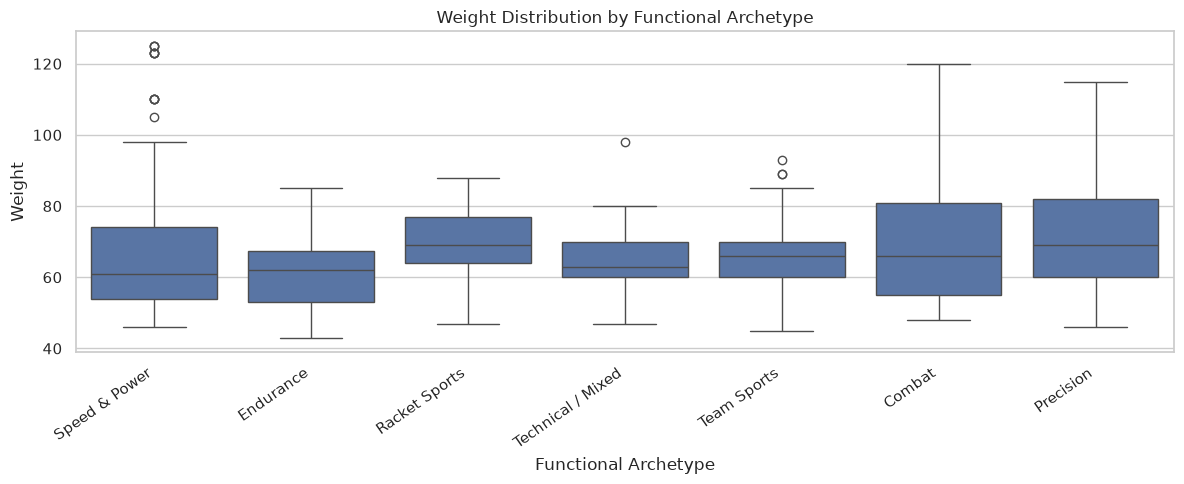

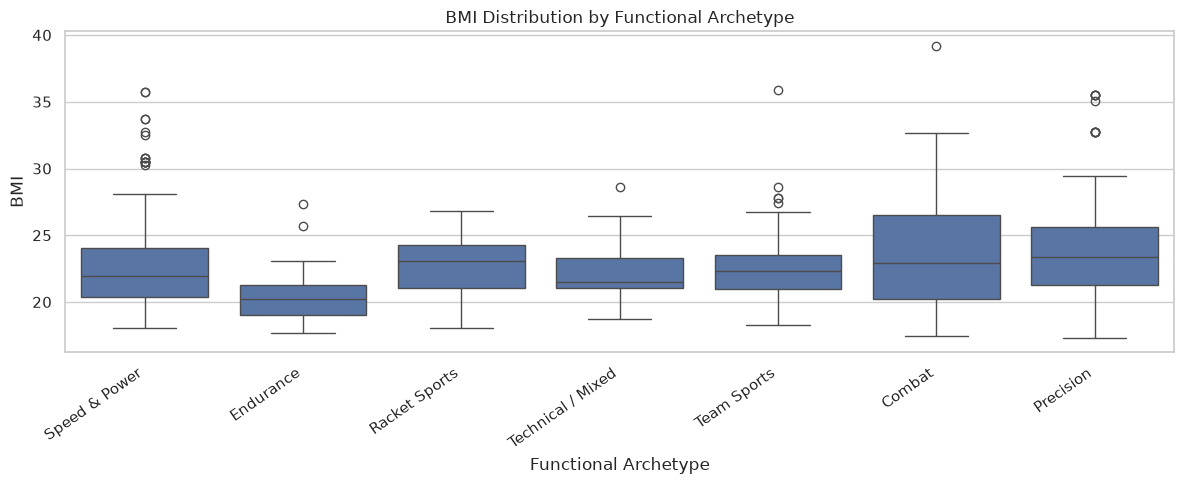

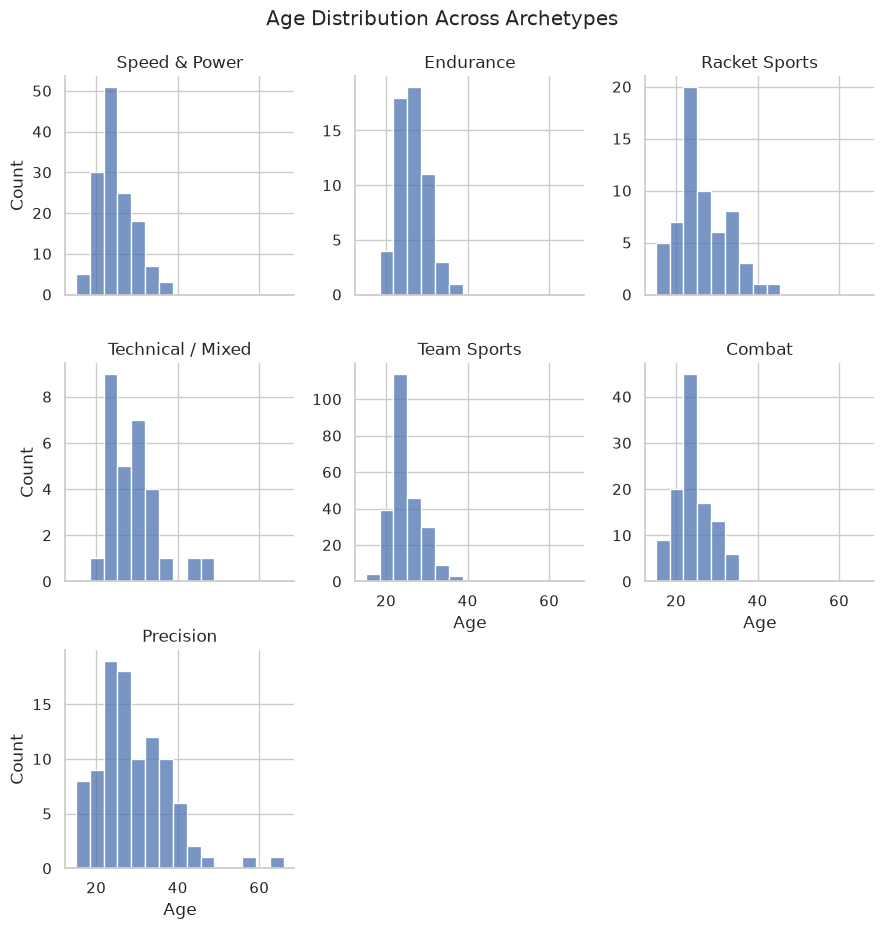

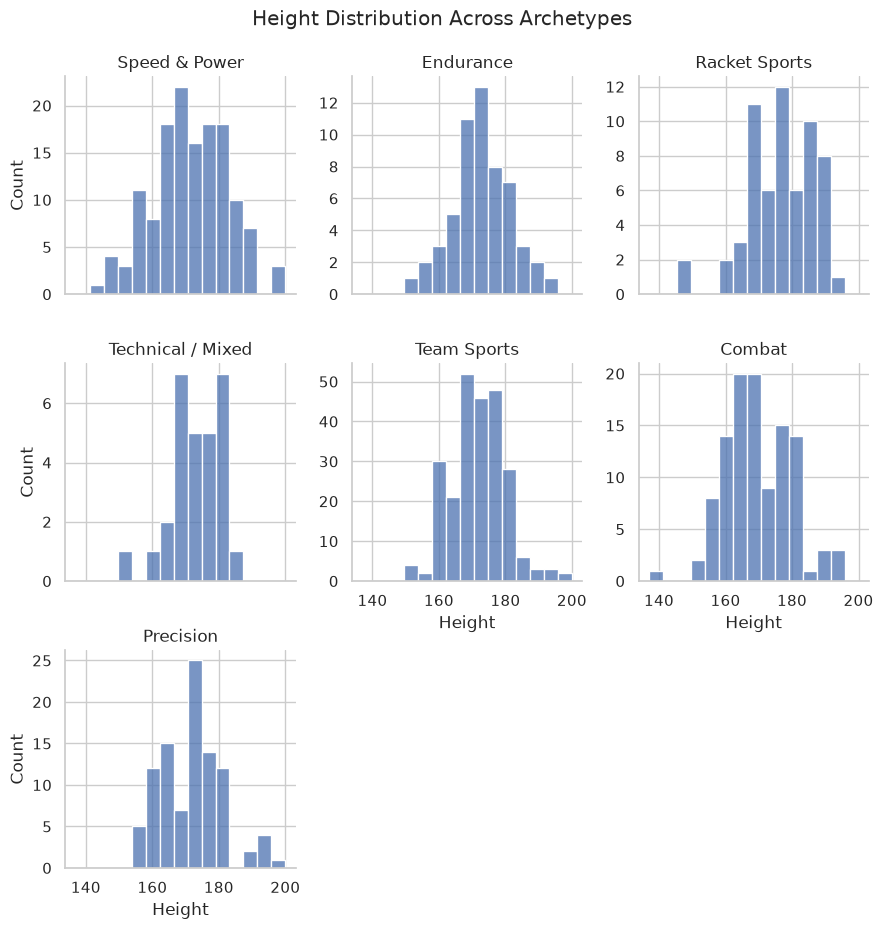

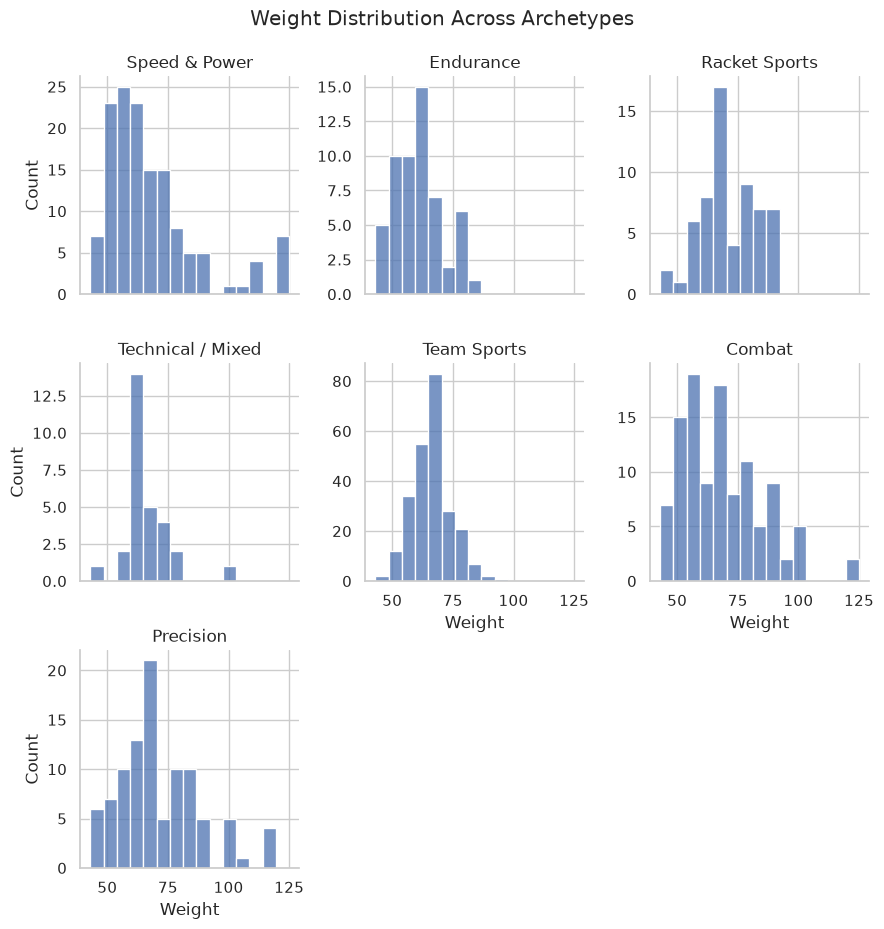

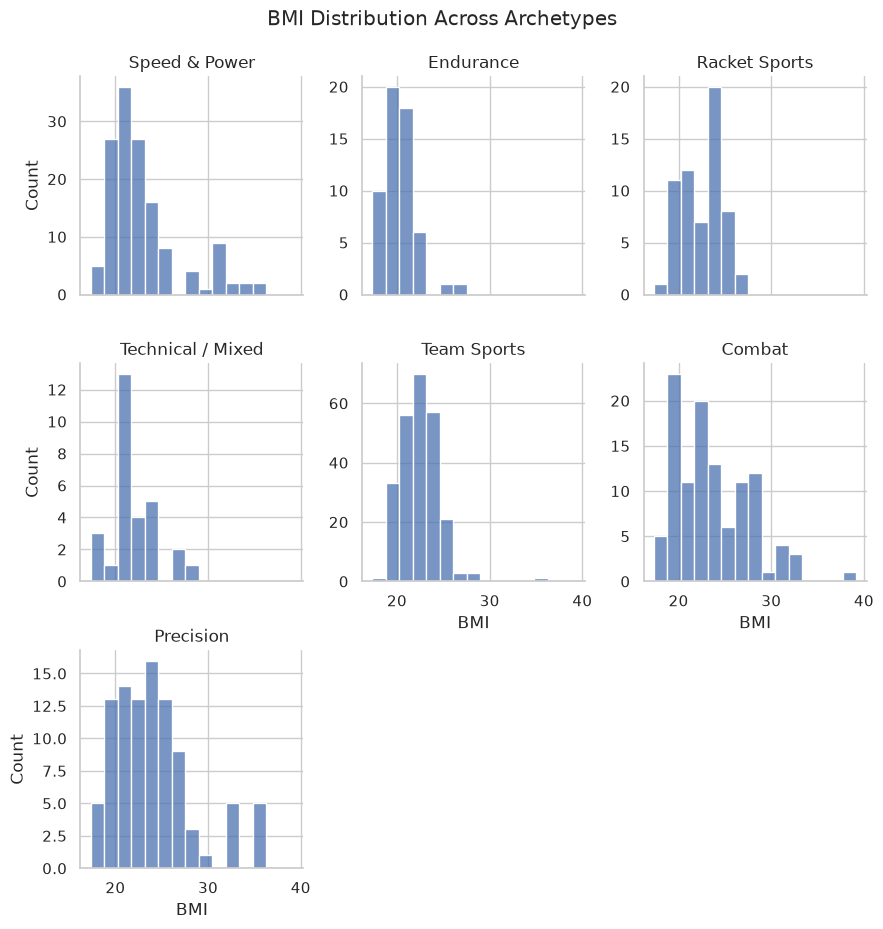

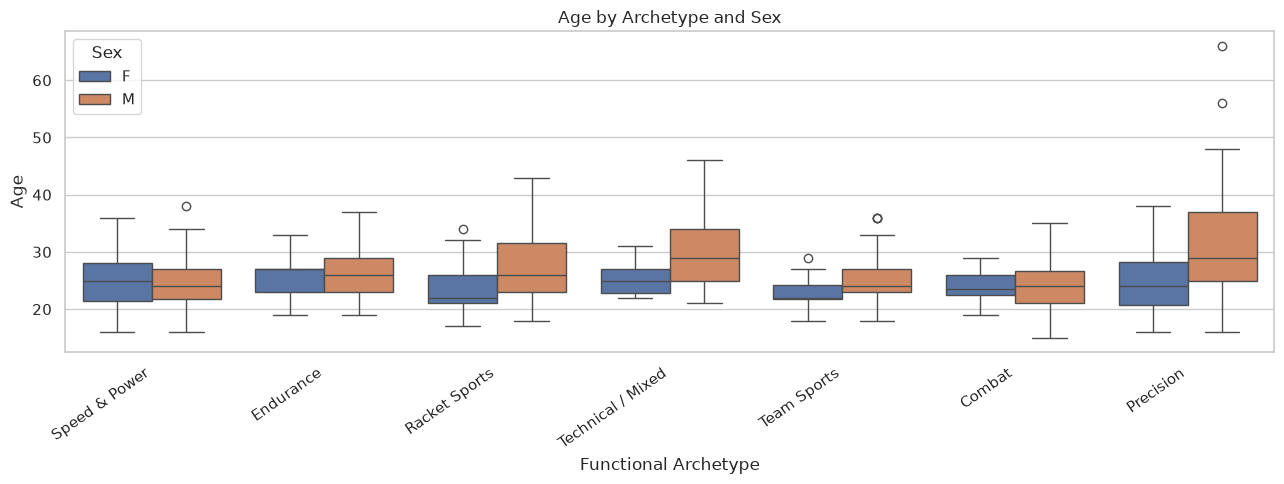

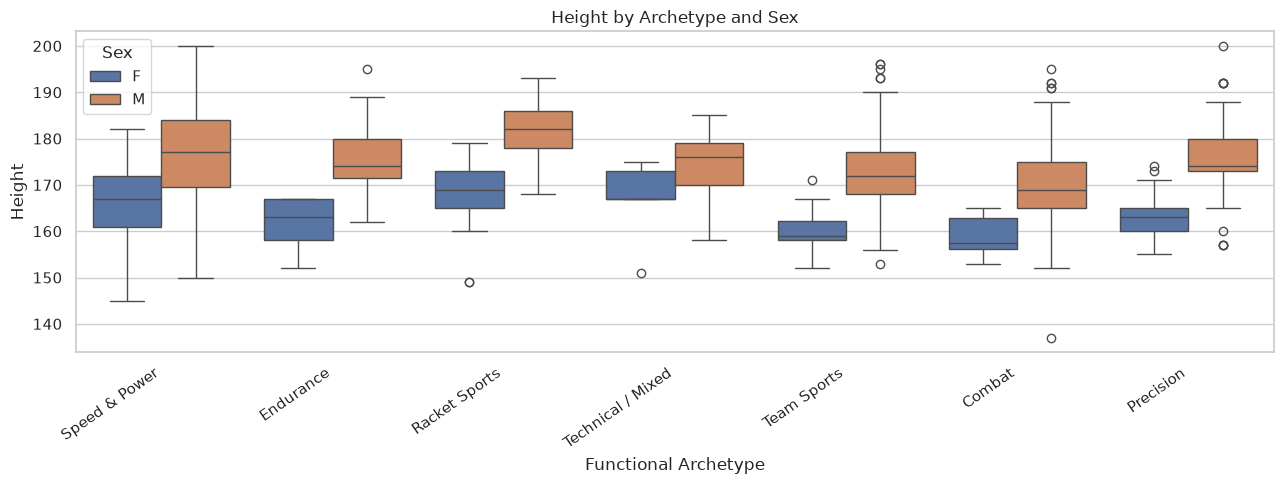

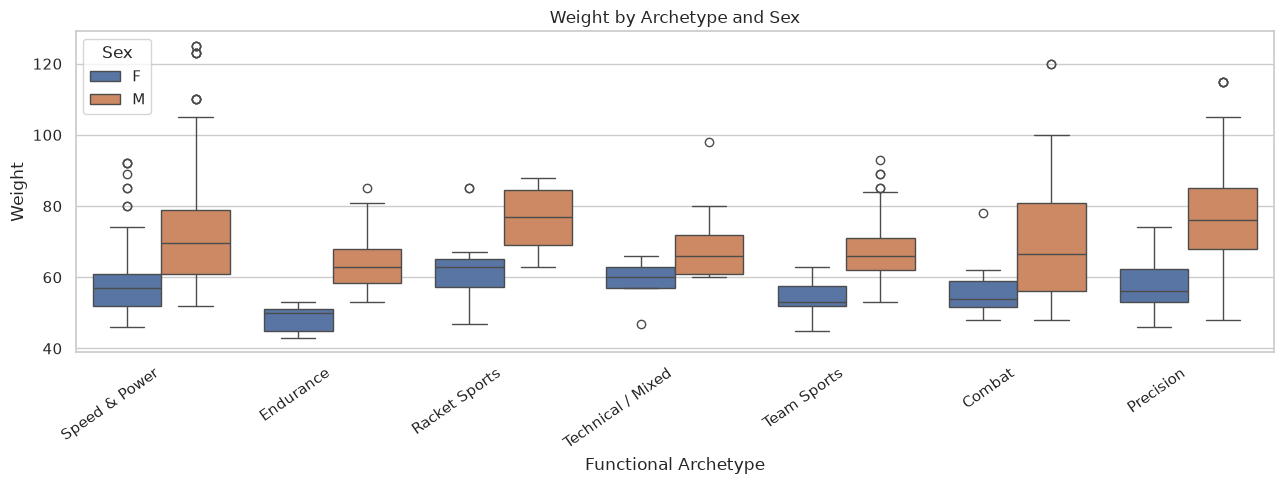

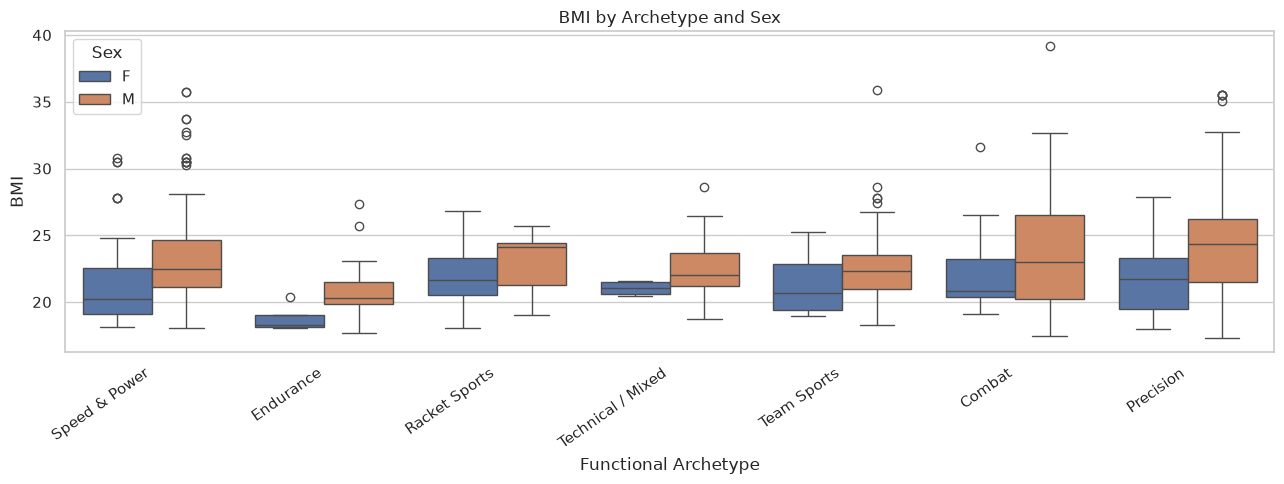

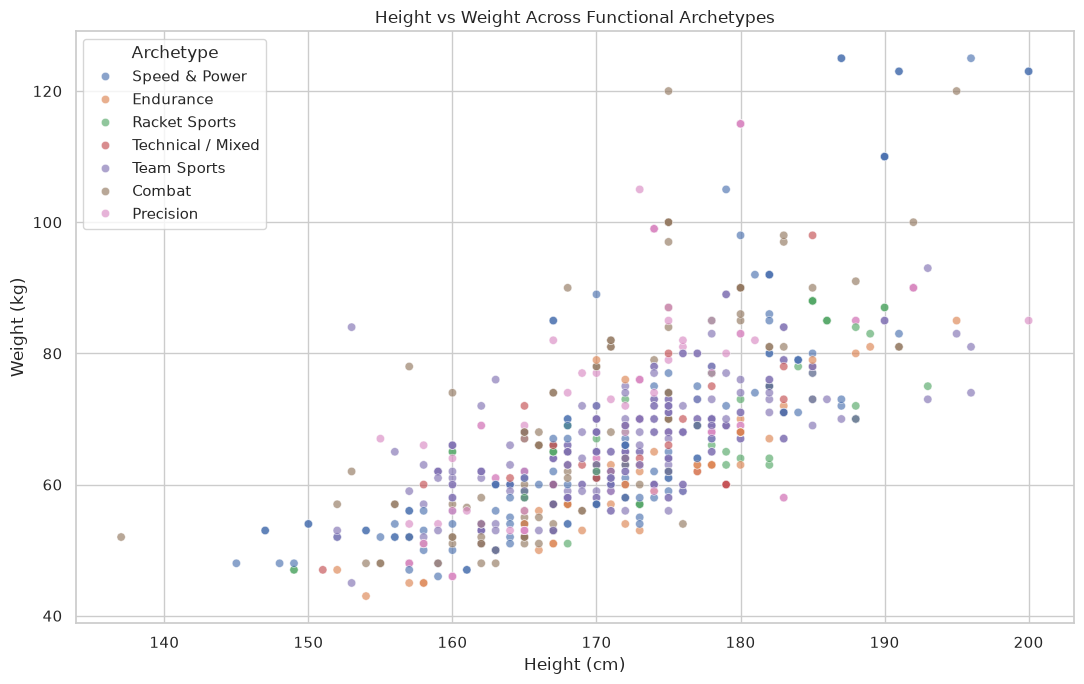

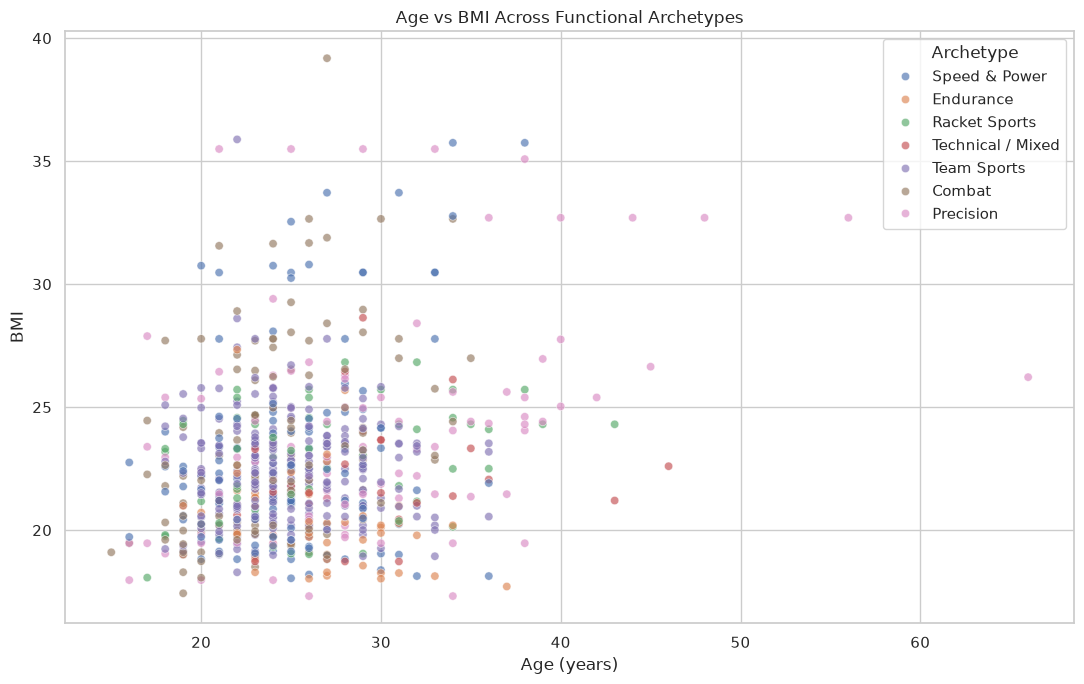

All 18 plots saved successfully in: /home/manu/DAI/project/q1_plots


In [14]:

from pathlib import Path

# Create folders if they don't exist
base = Path("q1_plots")

folders = {
    "mean": base / "mean_comparison",
    "box": base / "boxplots",
    "hist": base / "histograms",
    "sex": base / "sexwise_boxplots",
    "scatter": base / "scatterplots"
}

for folder in folders.values():
    folder.mkdir(parents=True, exist_ok=True)


# 1. Mean comparison bar charts
for metric in metrics:
    plt.figure(figsize=(12, 5))

    order = (
        df.groupby("Archetype")[metric]
        .mean().sort_values().index
    )

    sea.barplot(
        data=df, x="Archetype", y=metric,
        order=order, errorbar=None
    )

    plt.title(f"Mean {metric} Across Functional Archetypes")
    plt.xlabel("Functional Archetype")
    plt.ylabel(metric)
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()

    plt.savefig(folders["mean"] / f"{metric.lower()}_mean.png", dpi=300)
    plt.show()


# 2. Boxplots
for metric in metrics:
    plt.figure(figsize=(12, 5))

    sea.boxplot(
        data=df, x="Archetype", y=metric
    )

    plt.title(f"{metric} Distribution by Functional Archetype")
    plt.xlabel("Functional Archetype")
    plt.ylabel(metric)
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()

    plt.savefig(folders["box"] / f"{metric.lower()}_boxplot.png", dpi=300)
    plt.show()


# 3. Histograms by archetype
for metric in metrics:
    g = sea.displot(
        data=df, x=metric,
        col="Archetype", col_wrap=3,
        bins=15, height=3,
        facet_kws={"sharex": True, "sharey": False}
    )

    g.set_titles("{col_name}")
    g.fig.suptitle(
        f"{metric} Distribution Across Archetypes",
        y=1.03
    )

    g.savefig(
        folders["hist"] / f"{metric.lower()}_histograms.png",
        dpi=300, bbox_inches="tight"
    )
    plt.show()


# 4. Sex-wise boxplots
for metric in metrics:
    plt.figure(figsize=(13, 5))

    sea.boxplot(
        data=df, x="Archetype",
        y=metric, hue="Sex"
    )

    plt.title(f"{metric} by Archetype and Sex")
    plt.xlabel("Functional Archetype")
    plt.ylabel(metric)
    plt.xticks(rotation=35, ha="right")
    plt.legend(title="Sex")
    plt.tight_layout()

    plt.savefig(
        folders["sex"] / f"{metric.lower()}_sexwise.png",
        dpi=300
    )
    plt.show()


# 5. Height vs Weight scatter plot
plt.figure(figsize=(11, 7))

sea.scatterplot(
    data=df, x="Height", y="Weight",
    hue="Archetype", alpha=0.65
)

plt.title("Height vs Weight Across Functional Archetypes")
plt.xlabel("Height (cm)")
plt.ylabel("Weight (kg)")
plt.tight_layout()

plt.savefig(
    folders["scatter"] / "height_vs_weight.png",
    dpi=300
)
plt.show()


# 6. Age vs BMI scatter plot
plt.figure(figsize=(11, 7))

sea.scatterplot(
    data=df, x="Age", y="BMI",
    hue="Archetype", alpha=0.65
)

plt.title("Age vs BMI Across Functional Archetypes")
plt.xlabel("Age (years)")
plt.ylabel("BMI")
plt.tight_layout()

plt.savefig(
    folders["scatter"] / "age_vs_bmi.png",
    dpi=300
)
plt.show()

print("All 18 plots saved successfully in:", base.resolve())
